# 03 Offline Augmentation QA

**Objective:** generate only real train-only augmentation files, visually check realism, and freeze the combined training manifest.

**Success criteria:** labels are copied unchanged, validation/test are untouched, one QA contact sheet is reviewed, and no original image is duplicated into an experiment folder.


## Setup and source manifest

Use an explicit split run when supplied; otherwise resolve the latest completed split run. `REGENERATE=False` prevents accidental overwrite of existing generated targets.


In [1]:
# Purpose: initialize train-only offline augmentation from a completed split artifact.
# Inputs: an explicit split run when provided, otherwise the latest run containing train_original.txt.
# Guard: require current-format test fingerprint metadata and default REGENERATE=False to prevent overwrite.
# Output: a unique augmentation run containing copied small manifests and source-run provenance.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import display

from src.analysis.plot_utils import plot_augmentation_contact_sheet
from src.artifacts import (
    create_run,
    find_latest_run,
    open_run,
    read_run_metadata,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.augmentation.offline import (
    generate_offline_augmentations,
    summarize_augmentations,
)
from src.config import find_project_root, load_pipeline_config, resolve_project_path
from src.dataset.manifests import (
    copy_manifest,
    manifest_sha256,
    read_manifest,
    write_manifest,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
DATASET_CONFIG = CONFIG["dataset"]
SEED = int(DATASET_CONFIG["random_seed"])
SOURCE_SPLIT_RUN = (
    None  # Set to a specific artifact directory to avoid implicit latest-run selection.
)
REGENERATE = False
SPLIT_RUN = (
    open_run(SOURCE_SPLIT_RUN)
    if SOURCE_SPLIT_RUN
    else find_latest_run(V2_ROOT, "split-manifests", "manifests/train_original.txt")
)
SPLIT_METADATA = read_run_metadata(SPLIT_RUN)
if SPLIT_METADATA.get("status") != "completed" or not SPLIT_METADATA.get(
    "test_pair_content_sha256"
):
    raise RuntimeError("Notebook 03 requires a completed current-format split run")
RUN = create_run(V2_ROOT, "augmentation-qa", "offline-cctv", SEED)
for manifest_name in ("train_original.txt", "val.txt", "test.txt"):
    copy_manifest(SPLIT_RUN.manifests / manifest_name, RUN.manifests / manifest_name)
write_run_metadata(
    RUN,
    {
        "stage": "augmentation-qa",
        "status": "started",
        "seed": SEED,
        "source_split_run": SPLIT_RUN.run_id,
        "test_pair_content_sha256": SPLIT_METADATA["test_pair_content_sha256"],
        "runtime": runtime_metadata(V2_ROOT),
    },
)

WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260825T170220Z_augmentation-qa_offline-cctv_s42_027537d/run.yaml')

## Generate train-only offline variants

**Input:** `train_original.txt` only.

**Expected result:** deterministic IR, sunlight/glare, and blur/compression samples. These transforms do not move boxes, so each output label must be byte-identical to its source label.


In [2]:
# Purpose: generate only the configured non-geometric robustness variants.
# Inputs: train_original.txt, global augmented-data destination, transform ratios, and deterministic seed.
# Guard: validation/test are never read; labels are copied unchanged and existing targets fail safely.
# Output: one row per generated pair and one compact per-transform summary CSV.
augmented_root = resolve_project_path(V2_ROOT, DATASET_CONFIG["generated"]["augmented"])
augmentation_report_df = generate_offline_augmentations(
    RUN.manifests / "train_original.txt",
    augmented_root,
    CONFIG["augmentation"]["offline_augmentation"],
    seed=SEED,
    overwrite=REGENERATE,
)
augmentation_summary_df = summarize_augmentations(augmentation_report_df)
augmentation_summary_path = RUN.csv / "offline_augmentation_summary.csv"
augmentation_summary_df.to_csv(augmentation_summary_path, index=False)
display(augmentation_summary_df)

,augmentation_type,generated_images
0,blur_compression,87
1,ir,217
2,sunlight,130


#### Observation

TODO after execution:

- Confirm generated counts match configured ratios.
- Record any transform that appears too strong or unrealistic.
- Do not accept geometric label reuse.


## Visual QA

**Input:** a bounded sample of generated pairs.

**Expected result:** one labeled contact sheet showing original and transformed images side-by-side.


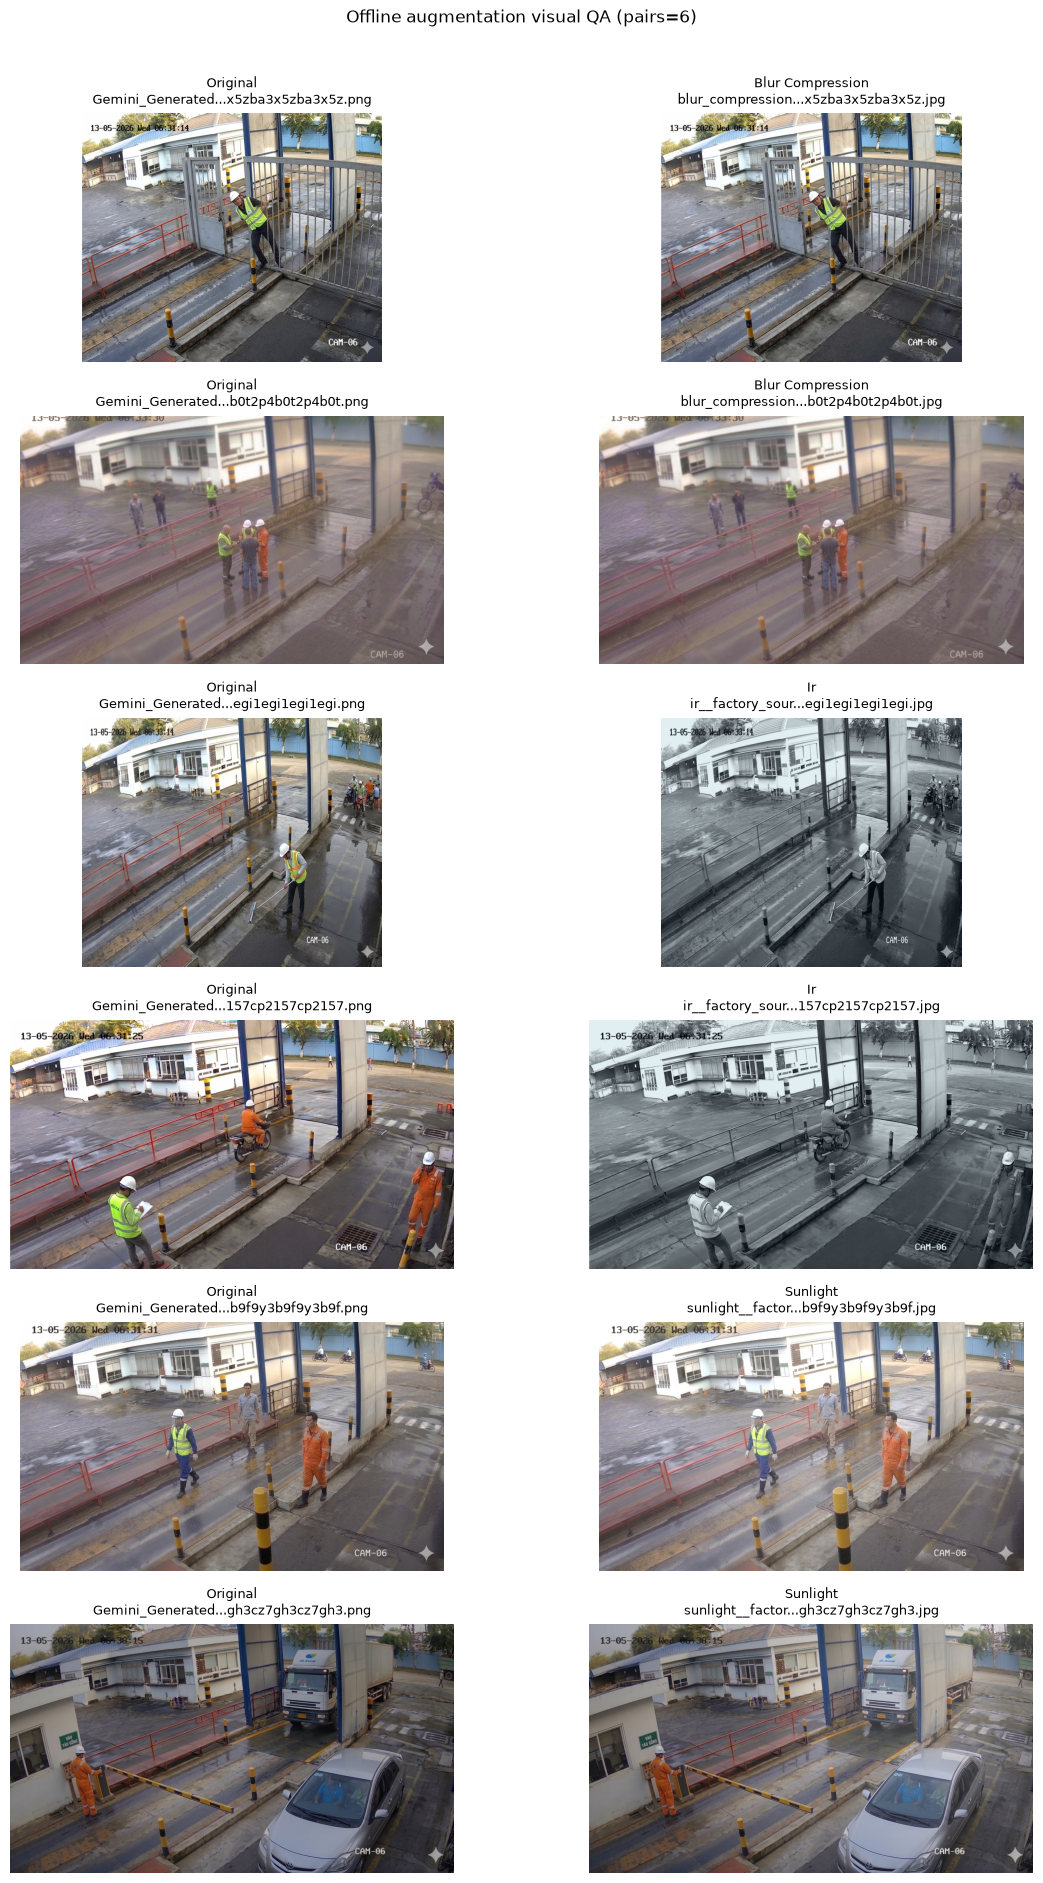

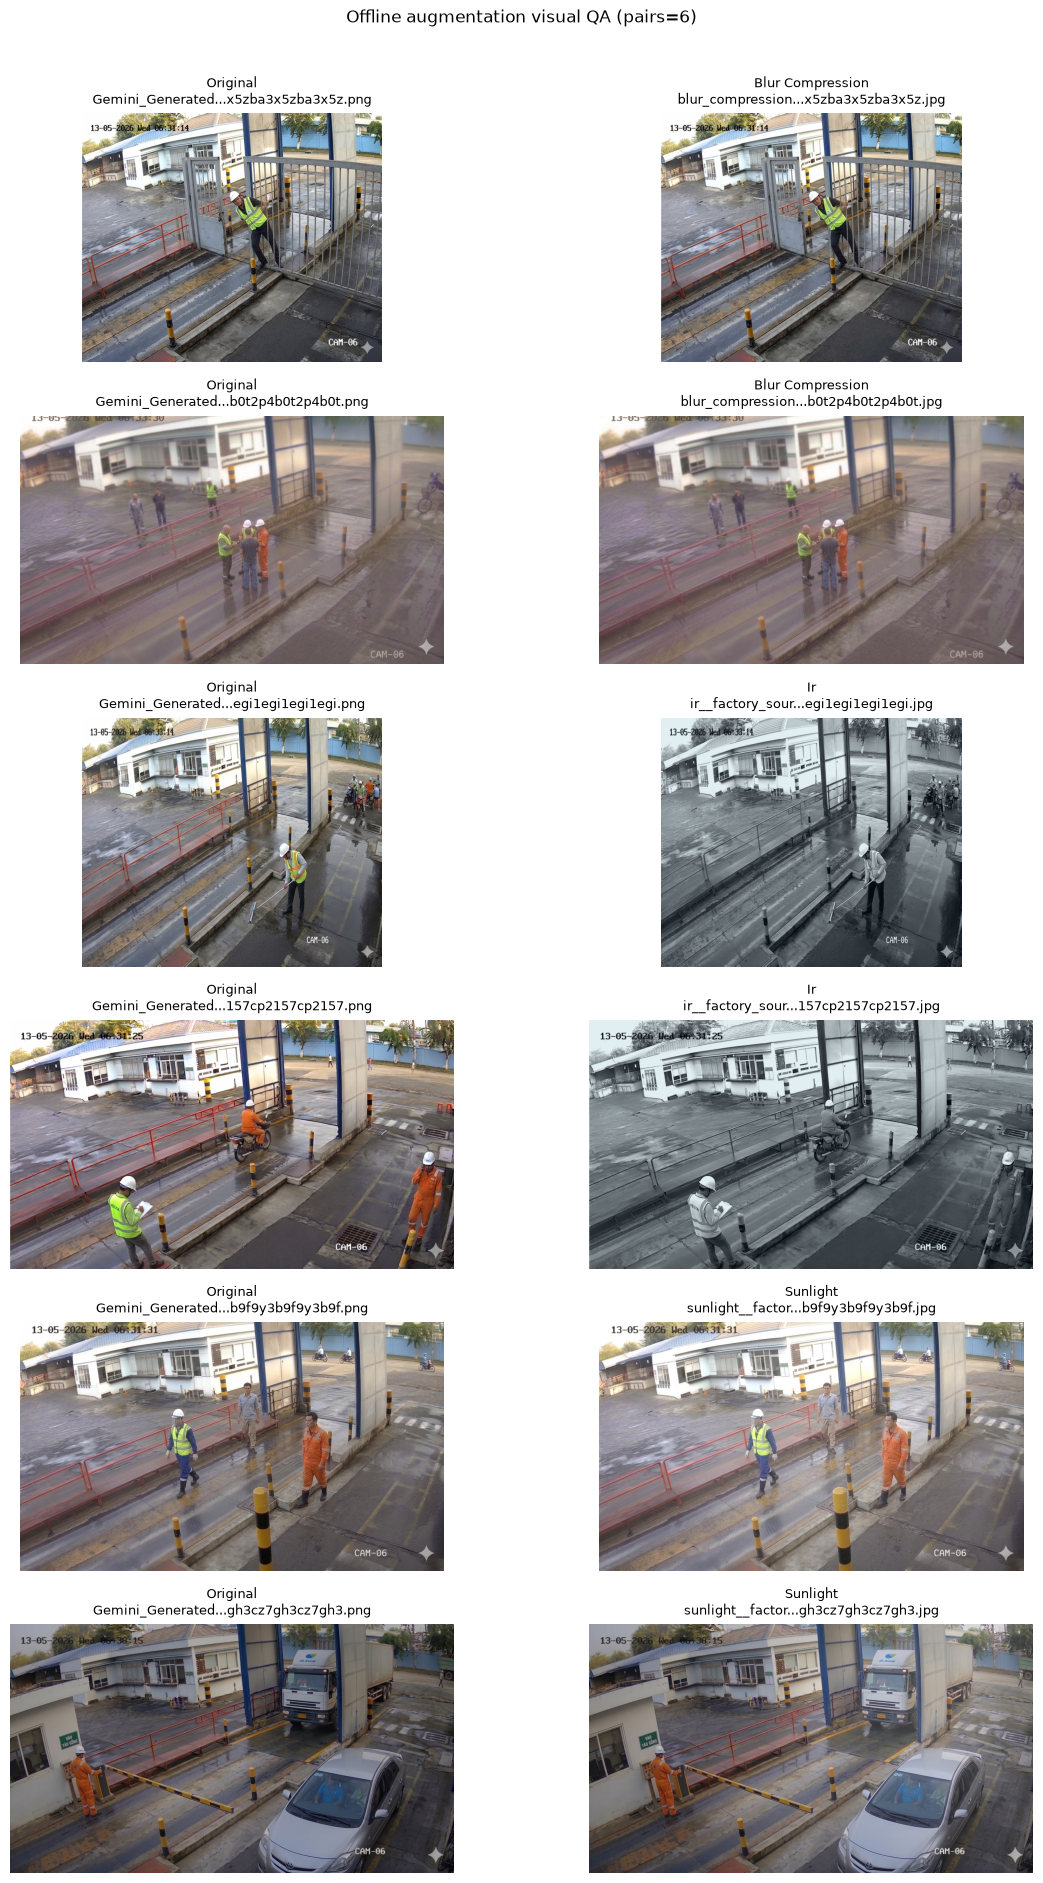

In [3]:
# Purpose: visually verify transform realism and label-safe appearance before training.
# Inputs: a bounded deterministic subset of successfully generated original/augmented pairs.
# Guard: use a wider two-column layout and compact long filenames so neighboring titles cannot overlap.
# Output: one before/after contact sheet with transform captions and middle-truncated filenames.
qa_figure_path = RUN.figures / "offline_augmentation_before_after.png"
qa_figure = plot_augmentation_contact_sheet(
    augmentation_report_df,
    qa_figure_path,
    samples_per_transform=2,
)
display(qa_figure)

#### Observation

TODO after execution:

- Assess whether PPE color/shape remains recognizable.
- Note glare, contrast, or compression settings that should be adjusted before training.
- Explicitly accept or reject the generated pool.


## Freeze original-plus-offline membership

Create a second training manifest from original paths plus only the images generated by this accepted run. Validation and test manifests remain unchanged.


In [4]:
# Purpose: freeze the only augmented training membership accepted by this run.
# Inputs: original manifest plus augmented paths from the current in-memory generation report.
# Guard: exclude stale files already present in data/generated/augmented and leave val/test unchanged.
# Output: train_original_plus_offline.txt and a four-row manifest count summary.
original_paths = read_manifest(RUN.manifests / "train_original.txt")
accepted_augmented_paths = [
    Path(path) for path in augmentation_report_df["augmented_image_path"]
]
combined_manifest = write_manifest(
    RUN.manifests / "train_original_plus_offline.txt",
    [*original_paths, *accepted_augmented_paths],
)
manifest_counts_df = pd.DataFrame(
    [
        {"manifest": "train_original", "images": len(original_paths)},
        {
            "manifest": "train_original_plus_offline",
            "images": len(read_manifest(combined_manifest)),
        },
        {"manifest": "val", "images": len(read_manifest(RUN.manifests / "val.txt"))},
        {"manifest": "test", "images": len(read_manifest(RUN.manifests / "test.txt"))},
    ]
)
display(manifest_counts_df)

,manifest,images
0,train_original,867
1,train_original_plus_offline,1301
2,val,172
3,test,117


#### Observation

TODO after execution: confirm only training membership grew and record the accepted original/augmented ratio.


## Finalize the augmentation record

Persist only compact counts, one QA figure, four small manifests, and reproducibility metadata.


In [5]:
# Purpose: finalize augmentation provenance for downstream candidate and ablation runs.
# Inputs: all run-local manifests, compact summary CSV, QA figure, and generated-image count.
# Guard: store hashes of frozen membership so downstream runs can copy exact manifests, not rediscover files.
# Output: completed run.yaml with only decision-relevant artifact references.
manifest_names = (
    "train_original.txt",
    "train_original_plus_offline.txt",
    "val.txt",
    "test.txt",
)
manifest_hashes = {
    name: manifest_sha256(RUN.manifests / name) for name in manifest_names
}
update_run_metadata(
    RUN,
    {
        "status": "completed",
        "augmentation_summary_csv": str(augmentation_summary_path),
        "qa_figure": str(qa_figure_path),
        "manifest_sha256": manifest_hashes,
        "generated_images": int(len(augmentation_report_df)),
    },
)
print(f"Augmentation run: {RUN.run_id}")
print(f"Generated images: {len(augmentation_report_df):,}")

Augmentation run: 20260825T170220Z_augmentation-qa_offline-cctv_s42_027537d
Generated images: 434


#### Observation

TODO after execution: record this accepted augmentation run ID for candidate selection and ablation.
